# Advection in 2D

We solve three problems:

**Part I.** Linear advection with a constant velocity,

$$\frac{\partial u}{\partial t} + c_x \frac{\partial u}{\partial x} + c_y \frac{\partial u}{\partial y} = 0,$$

We do not use the nested for loops though as in Barba's Step 5.

**Part II.** Nonlinear advection, where the velocity is the solution itself and we need one equation per component. Also, motivated by Barba 's Step 6.

**Part III.** Conservation form against non-conservative form on a discontinuity, repeating the measurement of nb09 in 2D.

### Notation

$$x \to i\,, \qquad y \to j\,, \qquad t \to n,$$

so a value is $u_{i,j}^{\,n}$ and we store it as `u[i, j, n]`.

### The scheme

Backward differences in each direction, valid while both velocity components are positive:

$$u_{i,j}^{\,n+1} = u_{i,j}^{\,n} - C_x\left( u_{i,j}^{\,n} - u_{i-1,j}^{\,n} \right) - C_y\left( u_{i,j}^{\,n} - u_{i,j-1}^{\,n} \right),
\qquad C_x + C_y \le 1 .$$

## Set-up: libraries and the grid

In [31]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt

### 1. Domain Definition (grid creation):

In [32]:
# Limits
x_min, x_max = 0., 2.
y_min, y_max = 0., 2.

# Number of points
ni = 81
nj = 81

# Resolution
dx = (x_max - x_min)/(ni - 1)
dy = (y_max - y_min)/(nj - 1)

# Axes
x = np.linspace(x_min, x_max, ni)
y = np.linspace(y_min, y_max, nj)

X, Y = np.meshgrid(x, y, indexing = "ij")

### 2. Set up ICs/BCs:

The same square hat as nb10: $u = 2$ on $0.5 \le x, y \le 1$ and $u = 1$
elsewhere, with $u = 1$ held on the four sides.

In [33]:
def square_hat(x_mesh, y_mesh, lo = 0.5, hi = 1.0, u_low = 1., u_high = 2.):

    u_mat = np.full_like(x_mesh, u_low)
    u_mat[(x_mesh >= lo) & (x_mesh <= hi) & (y_mesh >= lo) & (y_mesh <= hi)] = u_high

    return u_mat

ics = square_hat(X, Y)

# Part I. Linear advection

### 1. Time discretisation:

We take $c_x = c_y = 1$ and set the time step from a Courant number of 0.2 in
each direction, so $C_x + C_y = 0.4$, inside the limit.

In [34]:
# Speeds
c_x = 1.
c_y = 1.

# Courant numbers
C_x = C_y = 0.2

dt = C_x*dx/c_x

# Time levels

nt = 101

t = np.arange(0., nt*dt, dt)

print(C_x, C_y)

0.2 0.2


### 2. Numerical integration:

In [35]:
def march_linear(ics_mat, Cx, Cy, n_levels):

    u_mat = np.zeros((ics_mat.shape[0], ics_mat.shape[1], n_levels))

    u_mat[:, :, 0] = ics_mat

    # time loop (index n)
    for n in range(1, n_levels):

        u_old = u_mat[:, :, n-1]

        u_new = u_old.copy()

        u_new[1:, 1:] = (u_old[1:, 1:] - Cx*(u_old[1:, 1:] - u_old[:-1, 1:]) - Cy*(u_old[1:, 1:] - u_old[1:, :-1]))

        u_new[0, :] = u_new[-1, :] = 1.
        u_new[:, 0] = u_new[:, -1] = 1.

        u_mat[:, :, n] = u_new

    return u_mat

### 3. Plotting the solution:

In [36]:
u_lin = march_linear(ics, C_x, C_y, nt)

#print(u_lin.shape)

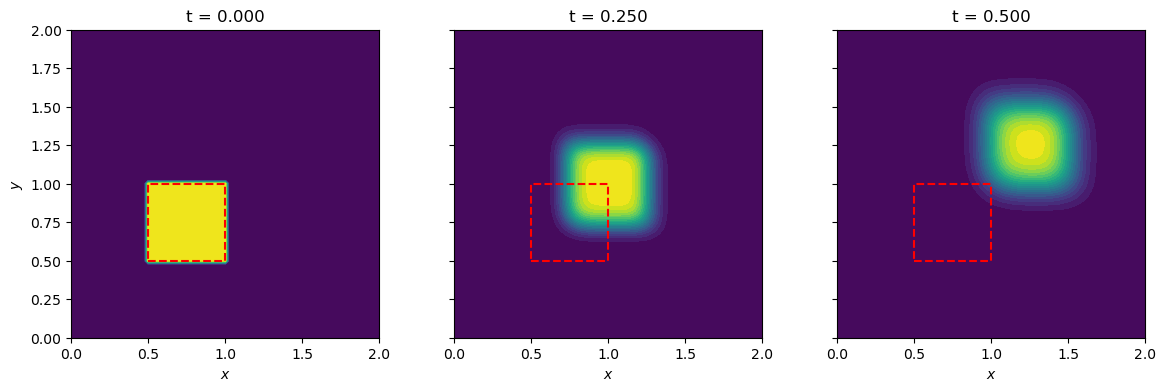

In [37]:
n_show = [0, 50, nt - 1]

fig, ax = plt.subplots(1, len(n_show), figsize = (14,4), sharey = True)

for a_i, n in zip(ax, n_show):

    a_i.contourf(X, Y, u_lin[:, :, n], levels = np.linspace(1., 2., 21))
    a_i.plot([0.5, 1., 1., 0.5, 0.5], [0.5, 0.5, 1., 1., 0.5],
             color = "r", lw = 1.5, ls = "--")
    a_i.set_title(f"t = {t[n]:.3f}")
    a_i.set_xlabel(r"$x$")
    a_i.set_aspect("equal")

ax[0].set_ylabel(r"$y$")

plt.show()

### Diffusion + Advection: 
The hat travels along the diagonal, as it must, and loses its corners on the way.
That smearing is due to numerical diffusion, now acting in two directions.

### 4. The stability limit:

The analysis gives $C_x + C_y \le 1$. Let's march a few steps at several
values and look at the largest value in the field.

In [38]:
# Courant numbers
C_x = C_y = 0.6

dt = C_x*dx/c_x

# Time levels

nt = 101

t = np.arange(0., nt*dt, dt)

print(C_x, C_y)

0.6 0.6


In [39]:
u_lin = march_linear(ics, C_x, C_y, nt)

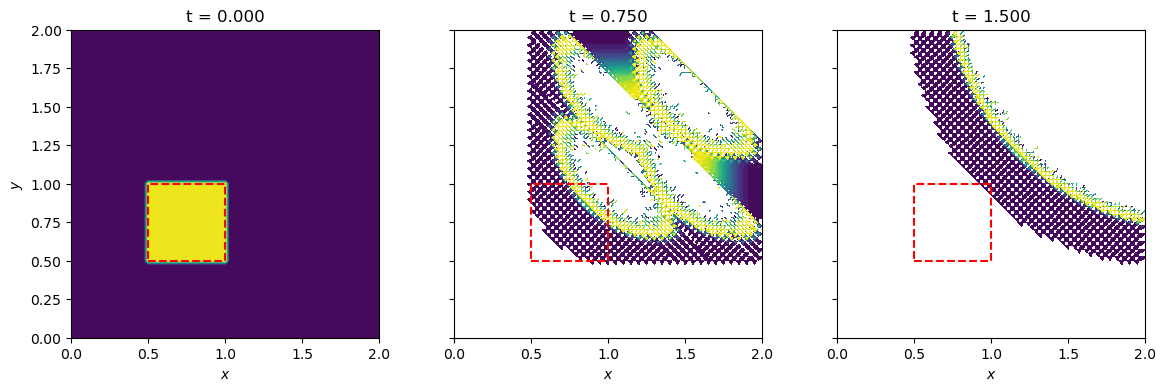

In [40]:
n_show = [0, 50, nt - 1]

fig, ax = plt.subplots(1, len(n_show), figsize = (14,4), sharey = True)

for a_i, n in zip(ax, n_show):

    a_i.contourf(X, Y, u_lin[:, :, n], levels = np.linspace(1., 2., 21))
    a_i.plot([0.5, 1., 1., 0.5, 0.5], [0.5, 0.5, 1., 1., 0.5],
             color = "r", lw = 1.5, ls = "--")
    a_i.set_title(f"t = {t[n]:.3f}")
    a_i.set_xlabel(r"$x$")
    a_i.set_aspect("equal")

ax[0].set_ylabel(r"$y$")

plt.show()

The two Courant numbers add. Each one on its own is well below the
one-dimensional limit of 1, and the march still fails once their sum passes
it.

# Part II. Nonlinear advection

Now the velocity is the solution itself, and it has two components:

$$\frac{\partial u}{\partial t} + u\frac{\partial u}{\partial x}
+ v\frac{\partial u}{\partial y} = 0, \qquad
\frac{\partial v}{\partial t} + u\frac{\partial v}{\partial x}
+ v\frac{\partial v}{\partial y} = 0 .$$

We march the pair together, using the local velocity in place of $c_x$ and
$c_y$.

In [50]:
def march_nonlinear(ics_u, ics_v, dt_num, n_levels):

    u_mat = np.zeros((ics_u.shape[0], ics_u.shape[1], n_levels))
    v_mat = np.zeros_like(u_mat)

    u_mat[:, :, 0] = ics_u
    v_mat[:, :, 0] = ics_v

    # time loop (index n)
    for n in range(1, n_levels):

        u_old = u_mat[:, :, n-1]
        v_old = v_mat[:, :, n-1]

        u_new = u_old.copy()
        v_new = v_old.copy()

        u_new[1:, 1:] = (u_old[1:, 1:] - u_old[1:, 1:]*dt_num/dx*(u_old[1:, 1:] - u_old[:-1, 1:]) - v_old[1:, 1:]*dt_num/dy*(u_old[1:, 1:] - u_old[1:, :-1]))

        v_new[1:, 1:] = (v_old[1:, 1:] - u_old[1:, 1:]*dt_num/dx*(v_old[1:, 1:] - v_old[:-1, 1:]) - v_old[1:, 1:]*dt_num/dy*(v_old[1:, 1:] - v_old[1:, :-1]))

        for a in (u_new, v_new):
            a[0, :] = a[-1, :] = 1.
            a[:, 0] = a[:, -1] = 1.

        u_mat[:, :, n] = u_new
        v_mat[:, :, n] = v_new

    return u_mat, v_mat

In [52]:
# The largest speed is 2, so the time step has to respect it
C_x = 0.2

dt_nl = C_x*dx/2.

nt_nl = 81

t_nl = np.arange(0., nt_nl*dt_nl, dt_nl)

u_nl, v_nl = march_nonlinear(ics, ics, dt_nl, nt_nl)

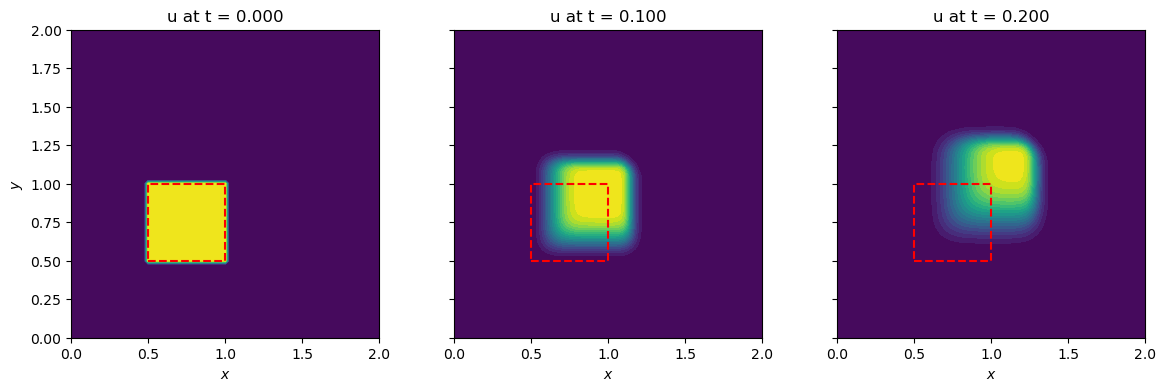

In [53]:
n_show = [0, 40, nt_nl - 1]

fig, ax = plt.subplots(1, len(n_show), figsize = (14,4), sharey = True)

for a_i, n in zip(ax, n_show):

    a_i.contourf(X, Y, u_nl[:, :, n], levels = np.linspace(1., 2., 21))
    a_i.plot([0.5, 1., 1., 0.5, 0.5], [0.5, 0.5, 1., 1., 0.5],
             color = "r", lw = 1.5, ls = "--")
    a_i.set_title(f"u at t = {t_nl[n]:.3f}")
    a_i.set_xlabel(r"$x$")
    a_i.set_aspect("equal")

ax[0].set_ylabel(r"$y$")

plt.show()

The high part of the hat travels faster than the low part, so the front face steepens and the back face stretches.

# Part III. Conservation form and the shock speed

For this part we use a scalar equation with a genuine flux vector,

$$\frac{\partial u}{\partial t} + \nabla\cdot\mathbf{F} = 0, \qquad
\mathbf{F} = \left(\frac{u^2}{2}, \frac{u^2}{2}\right)
\qquad \Longleftrightarrow \qquad
u_t + u\,u_x + u\,u_y = 0 .$$

The coupled pair of Part II has no divergence form unless $\nabla\cdot\mathbf{V} = 0$, so it cannot carry this comparison.

### 1. Eexact answer:

For a front whose normal points along $(p, q)$ the solution depends on the single variable $\zeta = px + qy$, and the Rankine-Hugoniot condition $s[u] = [\mathbf{F}]\cdot\mathbf{n}$ gives

$$s_\zeta = (p + q)\,\frac{u_1 + u_2}{2} .$$

So the same jump travels at a different speed depending on its orientation.

### 2. Set-up:

We use a periodic square of side $2\pi$ and a band of $u = 2$ on a background of $u = 1$. The grids here are large, so these functions carry two time levels instead of the full matrix.

In [54]:
# Periodic domain for Part III
L = 2.*np.pi

u_hi = 2.
u_lo = 1.

# Edges of the band in the phase variable
za, zb = 1., 3.
t_end = 0.3

def band(phase):

    z = np.mod(phase, L)

    u_vec = np.full_like(z, u_lo)
    u_vec[(z >= za) & (z <= zb)] = u_hi

    return u_vec

def exact_speed(p, q):

    return (p + q)*0.5*(u_hi + u_lo)


print(f"{'normal':>8s} {'exact speed':>13s}")
for p, q in [(1, 0), (1, 1), (2, 1), (3, 1)]:
    print(f"  ({p},{q}) {exact_speed(p, q):13.4f}")

  normal   exact speed
  (1,0)        1.5000
  (1,1)        3.0000
  (2,1)        4.5000
  (3,1)        6.0000


### 3. The two schemes:

Upwind differencing of the flux, against the same differencing applied to the
chain-rule form.

In [55]:
def march_burgers_2d(ni_num, form, p, q):

    xv = np.linspace(0., L, ni_num, endpoint = False)
    dxv = xv[1] - xv[0]

    Xv, Yv = np.meshgrid(xv, xv, indexing = "ij")

    u_mat = band(p*Xv + q*Yv)

    dt_num = 0.4*dxv/(u_hi*(p + q))
    n_steps = int(round(t_end/dt_num))
    dt_num = t_end/n_steps

    for n in range(n_steps):

        u_old = u_mat.copy()

        if form == "conservative":

            f_old = 0.5*u_old**2

            u_mat = (u_old
                     - dt_num/dxv*(f_old - np.roll(f_old, 1, axis = 0))
                     - dt_num/dxv*(f_old - np.roll(f_old, 1, axis = 1)))

        else:

            u_mat = (u_old
                     - u_old*dt_num/dxv*(u_old - np.roll(u_old, 1, axis = 0))
                     - u_old*dt_num/dxv*(u_old - np.roll(u_old, 1, axis = 1)))

    return xv, u_mat

### 4. Collapsing the field onto the phase variable:

Since the solution depends only on $\zeta = px + qy$, we average the field
over cells with the same $\zeta$ and measure the front on that profile.

In [56]:
def phase_profile(xv, u_mat, p, q, n_bins = 400):

    zeta = np.mod(p*xv[:, None] + q*xv[None, :], L)

    k = np.minimum((zeta/L*n_bins).astype(int), n_bins - 1)

    total = np.bincount(k.ravel(), weights = u_mat.ravel(), minlength = n_bins)
    count = np.bincount(k.ravel(), minlength = n_bins)

    return (np.arange(n_bins) + 0.5)*L/n_bins, total/count


def front_position(z_vec, u_vec):

    half = 0.5*(u_hi + u_lo)

    k = np.where((u_vec[:-1] >= half) & (u_vec[1:] < half))[0]

    if len(k) == 0:
        return np.nan

    i = k[0]

    return z_vec[i] + (u_vec[i] - half)/(u_vec[i] - u_vec[i+1])*(z_vec[1] - z_vec[0])

### 5. The front on the diagonal:

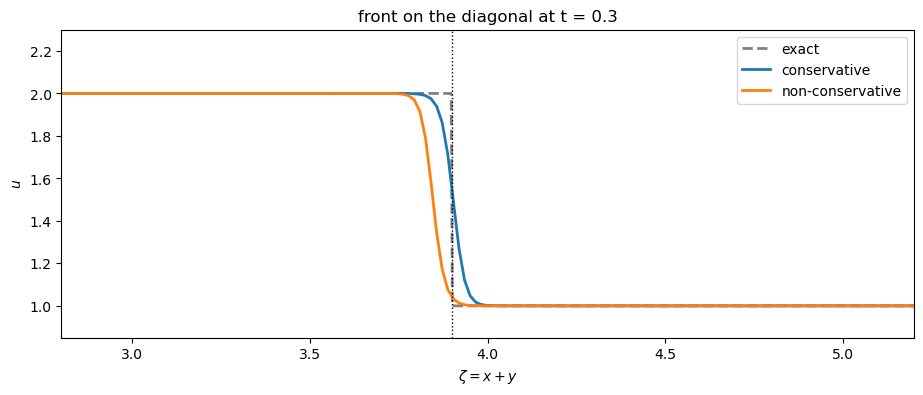

In [57]:
ni_s = 401

p, q = 1, 1

plt.figure(figsize=(11,4))

z_fine = np.linspace(0., L, 2000)

plt.plot(z_fine, band(z_fine - exact_speed(p, q)*t_end),
         color = "0.5", ls = "--", lw = 2, label = "exact")

for form in ("conservative", "non-conservative"):

    xv, u_mat = march_burgers_2d(ni_s, form, p, q)
    z_vec, prof = phase_profile(xv, u_mat, p, q)

    plt.plot(z_vec, prof, lw = 2, label = form)

plt.axvline(zb + exact_speed(p, q)*t_end, color = "k", lw = 1, ls = ":")

plt.xlabel(r"$\zeta = x + y$")
plt.ylabel(r"$u$")

plt.title(f"front on the diagonal at t = {t_end}")

plt.xlim(2.8, 5.2)
plt.ylim(0.85, 2.3)

plt.legend()

plt.show()

### 6. Four orientations:

In [58]:
cases = [(1, 0), (1, 1), (2, 1), (3, 1)]

speeds = {}

print(f"{'normal':>8s} {'exact':>9s} {'conservative':>14s} "
      f"{'non-cons.':>12s} {'error':>9s}")

for p, q in cases:

    row = []

    for form in ("conservative", "non-conservative"):

        xv, u_mat = march_burgers_2d(ni_s, form, p, q)
        z_vec, prof = phase_profile(xv, u_mat, p, q)
        row.append((front_position(z_vec, prof) - zb)/t_end)

    speeds[(p, q)] = row

    ex = exact_speed(p, q)

    print(f"  ({p},{q}) {ex:9.4f} {row[0]:14.4f} {row[1]:12.4f} "
          f"{100.*(row[1] - ex)/ex:8.2f} %")

  normal     exact   conservative    non-cons.     error
  (1,0)    1.5000         1.5066       1.3972    -6.85 %
  (1,1)    3.0000         3.0102       2.8201    -6.00 %
  (2,1)    4.5000         4.5155       4.2564    -5.41 %
  (3,1)    6.0000         6.0214       5.6852    -5.25 %


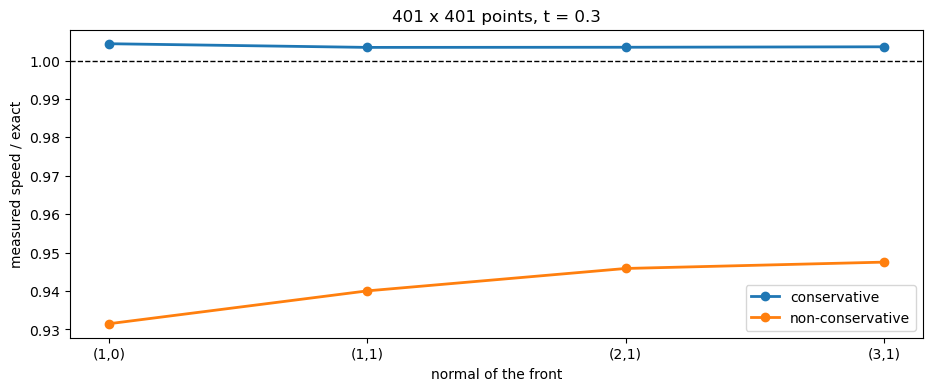

In [ ]:
plt.figure(figsize=(11,4))

xs = np.arange(len(cases))

for k, form in enumerate(["conservative", "non-conservative"]):
    plt.plot(xs, [speeds[c][k]/exact_speed(*c) for c in cases], marker = "o", lw = 2, label = form)

plt.axhline(1., color = "k", lw = 1, ls = "--")

plt.xticks(xs, [f"({p},{q})" for p, q in cases])

plt.xlabel("normal of the front")
plt.ylabel("measured speed / exact")

plt.title(f"{ni_s} x {ni_s} points, t = {t_end}")

plt.legend()

plt.show()

### Summary of results

- Part I: the hat is carried along the diagonal and its corners are rounded off. The two Courant numbers add, and the march fails as soon as $C_x + C_y$ passes 1, even though neither one alone reaches the 1D limit.

- Part II: with the velocity equal to the solution the front face steepens and the back face stretches, which is the two-dimensional version of Lecture 13.

- Part III: the conservative form reaches the Rankine-Hugoniot speed $(p+q)(u_1+u_2)/2$ at every orientation, to within half a percent. The non-conservative form is 5 to 7 % slow at all of them.

- The error of the non-conservative form is therefore not an artefact of the
  front being oblique to the mesh. It is the same missing telescoping sum as
  in one dimension, and it does not care how the front is oriented.